**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**10 | Temporal Architecture Engineering and Matched HARTH Development Benchmark**

![HARTH architecture and matched benchmark workflow](../../images/10_consolidated_workflow.svg)

**Objective:** Characterise four advanced temporal architectures and compare seven classifiers with participant-disjoint HARTH Development folds. Model-engineering checks and predictive evaluation share one source-window cohort, but have different and clearly separated purposes.

**Dataset:** Pinned official NTNU AI Lab HARTH v2.0. Six lower-back/thigh acceleration channels (nominal 50 Hz); eight documented source task codes; 100-sample, label-pure and time-continuous windows with a 50-sample stride. The 29 Development participants exclude S023 and S032. A label-independent 500-window per-person cap defines the matched benchmark.

**Integrated data flow:** Read and window the Development source once. Derive a four-person, 32-window-per-person engineering subset from the *same bounded cohort*, then use the complete bounded cohort for the seven-model, three-fold benchmark. This shared-cohort engineering subset differs from the historical standalone 32-cap functional-validation subset; functional validation-test outputs are engineering checks rather than matched predictive outcomes. The benchmark's source rows, fold strategy and training rules are unchanged.

**Methods:** Four distinct architectures (TCN, Multi-Scale CNN, 1D-ResNet and Time-Series Transformer) plus a Simple Temporal CNN capacity reference; input/logit checks, illustrative CPU inference timing, Train-only normalisation and single-update functional-validation checks; followed by Random Forest and six neural configurations in three participant-held-out folds (21 model–fold jobs). Neural fits use 400 Adam updates, batch size 128 and learning rate 0.001. Random Forest uses the approved 30-feature representation and 120 trees.

**Evidence:** The published run contains 35 stage-owned CSV/PNG outputs, including fixed-eight-class Macro F1, participant scores, class-wise precision/recall/F1, confusions, training/inference cost, architecture capacity and source-to-prediction alignment. The consolidated benchmark compared seven classifiers across three common folds.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Standard Library ----------------------------
import time

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# -------------- 5. Machine Learning and Deep Learning Framework --------------
import torch
from torch import nn
from core.feature_engineering import extract_signal_features

# ----------- 6. HARTH Source, Architecture and Benchmark Utilities -----------
from core.output_download import download_outputs_from_colab
from harth_data import (
    HARTH_SUBJECTS, HARTH_REVISION, ACTIVITY_NAMES, SENSOR_COLUMNS,
    prepare_harth_window_cohort,
)
from core.advanced_temporal_models import (
    ARCHITECTURES, build_temporal_model, count_trainable_parameters,
)
from core.temporal_cnn import TemporalCNN, standardise_imu_train_only
from core.temporal_benchmark import (
    MODEL_NAMES, PROTOCOL_VERSION, make_benchmark_plan,
    run_benchmark_job, summarise_benchmark_results,
)

# ------------------ 7. Reproducibility and Device Selection ------------------
from core.computer_device import computer_device

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = computer_device()
DEVICE = device.type

# -------------------- 8. Task and Current Output Settings --------------------
CLASSES = tuple(range(1, 9))
RESERVED_TEST = {"S023", "S032"}
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)

if len(SENSOR_COLUMNS) != 6 or len(CLASSES) != 8:
    raise ValueError("Expected the approved six-channel, eight-class task.")
print('Notebook 10 | temporal engineering and grouped Development benchmark')
print('Pinned HARTH revision:', HARTH_REVISION)
print('Source activity codes:', CLASSES)
print('Research output directory:', output_dir)
print('Protected assessment participants:', sorted(RESERVED_TEST))


Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Notebook 10 | temporal engineering and grouped Development benchmark
Pinned HARTH revision: dad2cfbe89a26f72f19770419469ac037de200df
Source activity codes: (1, 2, 3, 4, 5, 6, 7, 8)
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output
Protected assessment participants: ['S023', 'S032']


**02. Construct the Shared HARTH Development Cohort**

Build the approved 500-window-per-participant cohort **once** for both the engineering and benchmark analyses. Preserve the native six-channel tensor, original task codes and participant identifiers. Source windows are label-pure and time-continuous; the cap is label-blind. Show cohort and class support once here instead of reconstructing the same recordings later.

The original Test participants S023/S032 are excluded. Participant counts and class support are observations, not hard-coded pass criteria. Only invalid source/channel alignment or protected-person inclusion stops analysis.

In [3]:
# ============= 02. Construct the Shared HARTH Development Cohort =============

# ---------------- 1. Load and Window Development Participants ----------------
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
MAX_WINDOWS_PER_SUBJECT = 500
X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=CLASSES,
    max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,
    window_size=100,
    step_size=50,
    sampling_rate=50,
)

if X.ndim != 3 or X.shape[1:] != (len(SENSOR_COLUMNS), 100):
    raise ValueError(f"Unexpected six-channel window tensor shape: {X.shape}")
if len(X) != len(y) or len(y) != len(metadata):
    raise ValueError("Window tensor, labels and source metadata are not aligned.")
if set(metadata["subject_id"]) != set(DEVELOPMENT_SUBJECTS):
    raise ValueError("Development participant coverage differs from the defined cohort.")
if set(metadata["subject_id"]) & RESERVED_TEST:
    raise ValueError("Protected Test participants are present in Development.")
if not set(np.unique(y)).issubset(CLASSES):
    raise ValueError("Unexpected supervised activity labels.")

# ---------------- 2. Display the Cohort and Activity Coverage ----------------
counts = pd.crosstab(
    metadata["subject_id"], metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS, columns=CLASSES, fill_value=0)
coverage = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[c] for c in CLASSES],
    "windows": counts.sum(axis=0).to_numpy(),
    "supporting_subjects": (counts > 0).sum(axis=0).to_numpy(),
})
display(overview[["subject_id", "eligible_windows", "sampled_windows"]])
display(coverage)
print("Development tensor:", X.shape)
print("Expected / observed Development participants:", len(DEVELOPMENT_SUBJECTS), "/", metadata["subject_id"].nunique())
print("Bounded task windows:", len(X))
print("Label codes in the bounded cohort:", sorted(np.unique(y).tolist()))

# --------------- 3. Save Authoritative Shared-Cohort Evidence ----------------
overview.to_csv(output_dir / "10_development_cohort_summary.csv", index=False)
coverage.to_csv(output_dir / "10_development_activity_support.csv", index=False)


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


,activity,windows,supporting_subjects
0,Walking,3591,29
1,Running,1028,19
2,Shuffling,219,26
3,Stairs ascending,192,24
4,Stairs descending,182,25
5,Standing,2227,29
6,Sitting,5599,28
7,Lying,1163,23


Development tensor: (14201, 6, 100)
Expected / observed Development participants: 29 / 29
Bounded task windows: 14201
Label codes in the bounded cohort: [1, 2, 3, 4, 5, 6, 7, 8]


**03. Implement the Four Temporal Architectures**

**Temporal Convolutional Network (TCN):** Noncausal, residual dilated temporal blocks with dilations `1, 2, 4, 8`, two five-point convolutions per block, BatchNorm, GELU, Dropout and projection shortcuts. Global temporal pooling produces eight logits. It classifies completed windows, not streaming events.

**Multi-Scale CNN (InceptionTime-inspired):** Parallel temporal branches with kernels 3, 7 and 15 plus a max-pooling branch; input bottleneck, residual connections, BatchNorm and global pooling. This is a compact multi-scale design, not an implementation of the full published InceptionTime ensemble.

**1D-ResNet:** Initial temporal convolution, three residual stages, strided time downsampling in the second stage and projection shortcuts where channels change. Global pooling yields an eight-class result; residual connections alone do not guarantee better accuracy.

**Time-Series Transformer:** Six inputs projected to a 48-dimensional embedding, sinusoidal positional encodings, two bidirectional encoder layers, four attention heads, normalisation and mean pooling. Attention weights are not faithful explanations.

All architectures use the same `(batch, 6, 100)` float32 input interface and produce unnormalised `(batch, 8)` logits for Cross-Entropy. The architecture designs correspond to distinct hypotheses, not isolated causal interventions.

In [4]:
# =============== 03. Implement the Four Temporal Architectures ===============

# -------------- 1. Instantiate the Four Approved Architectures ---------------
architectures = {
    name: build_temporal_model(name, in_channels=6, n_classes=len(CLASSES))
    for name in ARCHITECTURES
}
sample = torch.randn(3, len(SENSOR_COLUMNS), 100)

# ----------- 2. Inspect the Common Model Input and Output Contract -----------
model_contracts = []
with torch.no_grad():
    for name, model in architectures.items():
        model.eval()
        logits = model(sample)
        if logits.shape != (len(sample), len(CLASSES)):
            raise ValueError(f"{name}: unexpected logit shape {tuple(logits.shape)}.")
        if not torch.isfinite(logits).all().item():
            raise ValueError(f"{name}: non-finite logits.")
        model_contracts.append({
            "architecture": name,
            "input_shape": str(tuple(sample.shape)),
            "logits_shape": str(tuple(logits.shape)),
        })
display(pd.DataFrame(model_contracts))


,architecture,input_shape,logits_shape
0,TCN,"(3, 6, 100)","(3, 8)"
1,Multi-Scale CNN,"(3, 6, 100)","(3, 8)"
2,1D-ResNet,"(3, 6, 100)","(3, 8)"
3,Time-Series Transformer,"(3, 6, 100)","(3, 8)"


**04. Compare Model Capacity and Illustrative CPU Inference**

Include the previously implemented Simple Temporal CNN as a reference alongside the four advanced architectures. Measure parameters and five CPU forward passes per model after warm-up using the same batch of synthetic inputs. The output-shape check is shared rather than repeated in four separate architecture cells. These CPU probes depend on hardware and PyTorch configuration; they are not a production-latency benchmark and cannot replace the measured training/inference costs in the participant-held-out evaluation.

,architecture,trainable_parameters,cpu_ms_per_16_windows,logits_shape
0,Simple Temporal CNN,12392,1.09,"(16, 8)"
1,TCN,38056,5.02,"(16, 8)"
2,Multi-Scale CNN,16488,4.12,"(16, 8)"
3,1D-ResNet,91176,4.92,"(16, 8)"
4,Time-Series Transformer,38744,8.06,"(16, 8)"


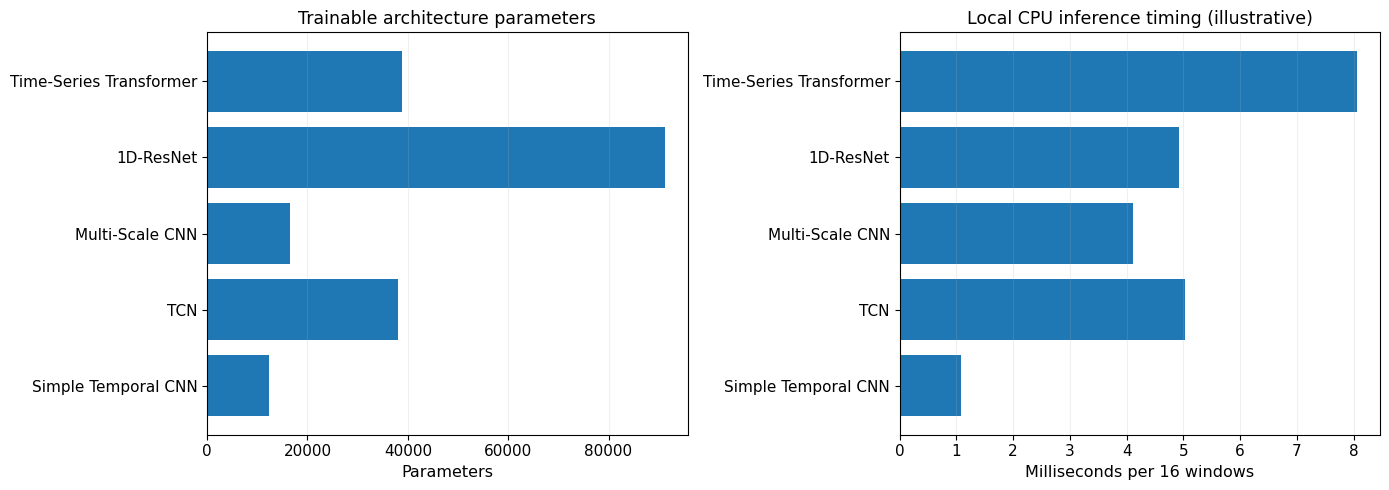

In [5]:
# ========= 04. Compare Model Capacity and Illustrative CPU Inference =========

# ------------------- 1. Configure Comparative Model Timing -------------------
models = {"Simple Temporal CNN": TemporalCNN(6, len(CLASSES)), **architectures}
timing_input=torch.randn(16,6,100)
rows=[]

# --------------------- 2. Measure CPU Forward-Pass Costs ---------------------
for name,model in models.items():
    model=model.cpu().eval()
    with torch.no_grad():
        for _ in range(2):
            logits=model(timing_input)
        starts=time.perf_counter()
        for _ in range(5):
            logits=model(timing_input)
        elapsed=(time.perf_counter()-starts)/5*1000  # Average over five CPU forward passes, in milliseconds.
    if logits.shape != (16, len(CLASSES)) or not torch.isfinite(logits).all().item():
        raise ValueError(f"{name}: invalid CPU inference output.")
    rows.append({
        "architecture":name,
        "trainable_parameters":count_trainable_parameters(model),
        "cpu_ms_per_16_windows":elapsed,
        "logits_shape":str(tuple(logits.shape))
    })
capacity=pd.DataFrame(rows)
display(capacity.round(2))

# ----------------------- 3. Summarise Model Complexity -----------------------
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].barh(capacity["architecture"],capacity["trainable_parameters"])
axes[0].set(title="Trainable architecture parameters",xlabel="Parameters")
axes[1].barh(capacity["architecture"],capacity["cpu_ms_per_16_windows"])
axes[1].set(title="Local CPU inference timing (illustrative)",xlabel="Milliseconds per 16 windows")
for ax in axes:
    ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_temporal_architecture_complexity_timing.png")
plt.show()


**05. Prepare the Architecture Functional-Validation Cohort**

Use S006, S008 and S012 as Train participants, and S013 as Validation. Select 32 evenly spaced windows per selected participant **from the already constructed 500-cap cohort**, without inspecting labels. This subset validates architectural functionality only; it is not the independent Validation cohort used in the seven-model benchmark. Its 32 windows per participant are derived from the existing capped Development tensor, without reloading source recordings.

Fit channel standardisation on the three Train participants alone, then apply it to the fourth person's windows. Report actual subject/window counts and label coverage. The full 29-person tensors and labels remain intact for the subsequent matched benchmark.

In [6]:
# ========= 05. Prepare the Architecture Functional-Validation Cohort =========

# ----------- 1. Select Source Windows Without Reloading Recordings -----------
ENGINEERING_PEOPLE = ["S006", "S008", "S012", "S013"]
training_people = set(ENGINEERING_PEOPLE[:3])
validation_people = {ENGINEERING_PEOPLE[3]}

if set(ENGINEERING_PEOPLE) & RESERVED_TEST or training_people & validation_people:
    raise ValueError("Engineering participant roles overlap with the Test or each other.")

engineering_rows = []
for participant in ENGINEERING_PEOPLE:
    participant_rows = np.flatnonzero(
        metadata["subject_id"].eq(participant).to_numpy()
    )
    if len(participant_rows) < 32:
        raise ValueError(f"Insufficient bounded windows for {participant}.")
    positions = np.linspace(0, len(participant_rows) - 1, 32, dtype=int)
    engineering_rows.append(participant_rows[positions])
engineering_rows = np.concatenate(engineering_rows)

X_engineering = X[engineering_rows]
engineering_labels = y[engineering_rows]
metadata_engineering = metadata.iloc[engineering_rows].reset_index(drop=True)

# --------- 2. Preserve Participant-Level Train/Validation Separation ---------
train_idx = np.flatnonzero(
    metadata_engineering["subject_id"].isin(training_people).to_numpy()
)
val_idx = np.flatnonzero(
    metadata_engineering["subject_id"].isin(validation_people).to_numpy()
)
if len(train_idx) < 16 or len(val_idx) == 0:
    raise ValueError("Engineering Train/Validation coverage is insufficient.")

X_train, X_validation, train_statistics = standardise_imu_train_only(
    X_engineering[train_idx], X_engineering[val_idx]
)
if not np.isfinite(X_train).all() or not np.isfinite(X_validation).all():
    raise ValueError("Train-only standardisation produced invalid values.")

# --------------------- 3. Describe Actual Source Support ---------------------
engineering_overview = overview.loc[
    overview["subject_id"].isin(ENGINEERING_PEOPLE)
].copy()
engineering_overview["sampled_windows"] = engineering_overview["subject_id"].map(
    metadata_engineering["subject_id"].value_counts()
).astype(int)
display(engineering_overview[["subject_id", "eligible_windows", "sampled_windows"]])
print("Engineering Train/Validation windows:", len(train_idx), "/", len(val_idx))
print("Engineering Train tensor:", X_train.shape)
print("Engineering Validation tensor:", X_validation.shape)
print("Observed Train classes:", sorted(np.unique(engineering_labels[train_idx]).tolist()))


,subject_id,eligible_windows,sampled_windows
0,S006,6708,32
1,S008,7392,32
4,S012,7309,32
5,S013,6402,32


Engineering Train/Validation windows: 96 / 32
Engineering Train tensor: (96, 6, 100)
Engineering Validation tensor: (32, 6, 100)
Observed Train classes: [1, 2, 3, 6, 7, 8]


**06. Perform One-Update Architecture Functional Validation**

For each advanced architecture, initialise an independent CPU model, fit one Adam update on the engineering Train subset and then evaluate logits on the held-out engineering participant. A valid functional-validation result requires finite loss, finite gradients, an actual parameter update and the correct eight-logit output shape. This is an implementation check, not a meaningful prediction-performance estimate.

In [7]:
# ========= 06. Perform One-Update Architecture Functional Validation =========

# -------------------- 1. Prepare Label and Tensor Inputs ---------------------
mapping={code:i for i,code in enumerate(CLASSES)}
batch_x=torch.from_numpy(X_train[:16])
batch_y=torch.tensor([mapping[int(label)] for label in engineering_labels[train_idx[:16]]],dtype=torch.long)
val_tensor=torch.from_numpy(X_validation)

# ---------------- 2. Run the One-Update Functional Validation ----------------
training_rows=[]
for name in ARCHITECTURES:
    torch.manual_seed(SEED)
    network=build_temporal_model(name,6,8).cpu()
    optimizer=torch.optim.Adam(network.parameters(),lr=1e-3)
    before=[weight.detach().clone() for weight in network.parameters()]
    network.train()
    optimizer.zero_grad(set_to_none=True)
    loss=nn.CrossEntropyLoss()(network(batch_x),batch_y)
    if not torch.isfinite(loss).item():
        raise RuntimeError(f"{name}: initial loss is non-finite.")
    loss.backward()
    if not all(
        parameter.grad is not None and torch.isfinite(parameter.grad).all().item()
        for parameter in network.parameters() if parameter.requires_grad
    ):
        raise RuntimeError(f"{name}: missing or non-finite gradients.")
    optimizer.step()
    changed=any(not torch.equal(old,current.detach())
                for old,current in zip(before,network.parameters()))

    # Apply the trained model to another participant without Validation fitting.
    network.eval()
    with torch.no_grad():
        validation_logits=network(val_tensor)
    if not changed or validation_logits.shape != (len(val_idx), len(CLASSES)):
        raise RuntimeError(f"{name}: invalid parameter update or output shape.")
    if not torch.isfinite(validation_logits).all().item():
        raise RuntimeError(f"{name}: non-finite held-out logits.")
    training_rows.append({
        "architecture":name,"initial_batch_loss":float(loss.item()),
        "optimizer_updates":1,"parameters_changed":changed,
        "held_out_output_shape":str(tuple(validation_logits.shape)),
        "finite_validation_logits":bool(torch.isfinite(validation_logits).all().item())
    })

# ----------------------- 3. Check Logits and Gradients -----------------------
functional_validation=pd.DataFrame(training_rows)

display(functional_validation.round(4))
print("Architecture functional validation completed; these checks are not classifier-performance results.")


,architecture,initial_batch_loss,optimizer_updates,parameters_changed,held_out_output_shape,finite_validation_logits
0,TCN,2.2744,1,True,"(32, 8)",True
1,Multi-Scale CNN,1.8451,1,True,"(32, 8)",True
2,1D-ResNet,2.1405,1,True,"(32, 8)",True
3,Time-Series Transformer,2.4455,1,True,"(32, 8)",True


Architecture functional validation completed; these checks are not classifier-performance results.


**07. Record Architecture Hypotheses and Functional-Validation Evidence**

Record modelling hypotheses, the main technical risks and the controls required for the subsequent seven-model comparison. This is one consolidated engineering export, not a second independent quality gate. The source-cohort summary, model size/timing measurements and single-update results have distinct scientific meanings; their tables and figures are retained without repeating the same display.

In [ ]:
# === 07. Record Architecture Hypotheses and Functional-Validation Evidence ===

# ------------------- 1. Summarise Architecture Hypotheses --------------------
design_map=pd.DataFrame([
    {"architecture":"TCN","hypothesis":"Dilated temporal context helps distinguish related movement sequences","principal_risk":"Noncausal window context and receptive-field assumptions"},
    {"architecture":"Multi-Scale CNN","hypothesis":"Parallel kernels capture multiple movement timescales","principal_risk":"More filters, extra optimisation and potentially noisy small activities"},
    {"architecture":"1D-ResNet","hypothesis":"Residual depth learns expressive sequence features","principal_risk":"Overfitting and stride-related information loss"},
    {"architecture":"Time-Series Transformer","hypothesis":"Bidirectional self-attention captures longer-range within-window patterns","principal_risk":"Computational cost and data hunger"},
])

display(design_map)

# ---------------- 2. Document Matched Benchmark Requirements -----------------
controls=pd.DataFrame([
    {"constraint":"Same windows and subject folds","status":"Required"},
    {"constraint":"Train-only sensor standardisation and class weights","status":"Required"},
    {"constraint":"Fixed eight-code class denominator and Macro F1","status":"Required"},
    {"constraint":"Per-class Shuffling/stairs performance and support","status":"Required"},
    {"constraint":"Compute/parameters/latency reporting","status":"Required"},
    {"constraint":"Original Test subjects S023/S032 excluded","status":"Required"},
    {"constraint":"Reproducibility over more than one seed","status":"Separate robustness analysis"},
])

display(controls)

# ------------------ 4. Retire Superseded Stage-Owned Names -------------------
for old_name in (
    "10_architecture_single_update_smoke_tests.csv",
    "10_smoke_source_cohort_summary.csv",
    "10_smoke_train_validation_people.csv",
):
    (output_dir / old_name).unlink(missing_ok=True)

# ----------------- 5. Save Architecture Validation Evidence ------------------
capacity.to_csv(output_dir / "10_architecture_capacity_cpu_timing.csv", index=False)
engineering_overview.to_csv(output_dir / "10_architecture_validation_cohort_summary.csv", index=False)
functional_validation.to_csv(output_dir / "10_architecture_functional_validation.csv", index=False)
design_map.to_csv(output_dir / "10_architecture_research_hypotheses.csv", index=False)
controls.to_csv(output_dir / "10_matched_benchmark_design_controls.csv", index=False)
pd.DataFrame([
    {"partition": role, "subject_id": person}
    for role, people in [
        ("train", sorted(training_people)),
        ("validation", sorted(validation_people)),
    ]
    for person in people
]).to_csv(output_dir / "10_architecture_validation_participants.csv", index=False)
print("Saved architecture engineering results in:", output_dir)


,architecture,hypothesis,principal_risk
0,TCN,Dilated temporal context helps distinguish rel...,Noncausal window context and receptive-field a...
1,Multi-Scale CNN,Parallel kernels capture multiple movement tim...,"More filters, extra optimisation and potential..."
2,1D-ResNet,Residual depth learns expressive sequence feat...,Overfitting and stride-related information loss
3,Time-Series Transformer,Bidirectional self-attention captures longer-r...,Computational cost and data hunger


,constraint,status
0,Same windows and subject folds,Required
1,Train-only sensor standardisation and class we...,Required
2,Fixed eight-code class denominator and Macro F1,Required
3,Per-class Shuffling/stairs performance and sup...,Required
4,Compute/parameters/latency reporting,Required
5,Original Test subjects S023/S032 excluded,Required
6,Reproducibility over more than one seed,Separate robustness analysis


Saved architecture engineering results in: /content/human-movement-intelligence/wearable_activity_recognition/output


**08. Specify the Matched Benchmark and Participant Folds**

The engineering subset above is not a Validation set for model selection. The full bounded cohort is used without reloading source files. Each of the seven models uses exactly the same three participant-disjoint GroupKFold partitions and the same original source-row identities.

The benchmark uses seed 42, 400 optimiser updates per neural fold, batch size 128 and learning rate `0.001`. The existing validated local cache is retained. A fingerprint of source windows and participant-fold assignment protects meaningful reuse; a missing or incompatible model–fold cache must be recomputed when training is executed.

In [ ]:
# ========== 08. Specify the Matched Benchmark and Participant Folds ==========

# ----------------- 1. Set the Approved Fixed Training Budget -----------------
FOLDS = 3
MAX_STEPS = 400
BATCH_SIZE = 128
CACHE_DIR = root / "data/processed/harth_stage23_matched_benchmark"
if len(MODEL_NAMES) != 7:
    raise ValueError("The established comparison requires seven classifier configurations.")
print("Approved benchmark protocol:", PROTOCOL_VERSION)
print("Models:", ", ".join(MODEL_NAMES))
print("Neural update budget:", MAX_STEPS, "| batch size:", BATCH_SIZE)

# -------------------- 2. Define Participant-Grouped Folds --------------------
plan=make_benchmark_plan(
    windows=X,labels=y,subject_ids=metadata["subject_id"].to_numpy(),
    classes=CLASSES,n_splits=FOLDS,forbidden_subjects=RESERVED_TEST
)

fold_design=[]

# -------------------- 3. Inspect Participant Separation ----------------------
for fold,tr,va in plan["folds"]:
    tr_groups=set(plan["groups"][tr])
    va_groups=set(plan["groups"][va])
    if tr_groups & va_groups:
        raise ValueError(f"Fold {fold} mixes Train and Validation participants.")
    fold_design.append({
        "fold":fold,"train_subjects":len(tr_groups),
        "validation_subjects":len(va_groups),
        "train_windows":len(tr),"validation_windows":len(va),
        "train_classes":len(np.unique(y[tr])),
        "validation_classes":len(np.unique(y[va])),
        "validation_subject_ids":", ".join(sorted(va_groups)),
    })

display(pd.DataFrame(fold_design))
print("Source SHA256:",plan["fingerprint"])
print("Complete model-by-fold jobs required:",len(MODEL_NAMES)*FOLDS)

# ---------------------- 4. Export Fold Membership ----------------------------
pd.DataFrame(fold_design).to_csv(output_dir / "10_matched_fold_design.csv", index=False)


Approved benchmark protocol: harth-stage23-matched-500cap-group3-fixed400-v1
Models: Random Forest, Standard CNN, Weighted CNN, TCN, Multi-Scale CNN, 1D-ResNet, Time-Series Transformer
Neural update budget: 400 | batch size: 128


,fold,train_subjects,validation_subjects,train_windows,validation_windows,train_classes,validation_classes,validation_subject_ids
0,1,19,10,9201,5000,8,8,"S006, S012, S015, S018, S021, S025, S028, S031..."
1,2,19,10,9500,4701,8,8,"S009, S010, S014, S017, S020, S024, S027, S030..."
2,3,20,9,9701,4500,8,8,"S008, S013, S016, S019, S022, S026, S029, S033..."


Source SHA256: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Complete model-by-fold jobs required: 21


**09. Define Model Representations and Training Rules**

Random Forest receives 30 deterministic statistical signal features; the six neural classifiers receive the same underlying `(6,100)` source windows. The Random Forest has 120 trees, minimum leaf size three and balanced-subsample weighting. Standard CNN uses ordinary Cross-Entropy; the other five neural configurations use inverse-square-root class weights computed on each fold's Train labels. Channel standardisation for neural models is also fitted on Train only.

These comparisons share the source cohort, folds and metric denominator, but differ in representation and architecture. Equal neural update counts do not imply equal FLOPs, parameter counts or convergence.

In [10]:
# ============ 09. Define Model Representations and Training Rules ============

# ----------------- 1. Specify Matched Model Representations ------------------
protocol=pd.DataFrame([
    {"model":name,"representation":
      "30 deterministic signal features" if name=="Random Forest" else "6 x 100 raw IMU",
     "training":
      "120-tree balanced-subset RF" if name=="Random Forest"
      else "400 Adam updates; inverse-sqrt weighted CE"
      if name!="Standard CNN" else "400 Adam updates; unweighted CE"}
    for name in MODEL_NAMES
])

display(protocol)

# --------------------- 2. Extract Random Forest Features ---------------------
features=extract_signal_features(X,channel_names=SENSOR_COLUMNS)
if features.shape != (len(X), 30):
    raise ValueError(f"Unexpected Random Forest feature shape: {features.shape}")
if not np.isfinite(features.to_numpy()).all():
    raise ValueError("Non-finite Random Forest features.")

rf_features=features.to_numpy()

print("RF feature matrix:",rf_features.shape)
print("RF and neural representations use the same bounded source rows.")

# ---------------------- 3. Export Model Protocols ----------------------------
protocol.to_csv(output_dir / "10_model_protocols.csv", index=False)


,model,representation,training
0,Random Forest,30 deterministic signal features,120-tree balanced-subset RF
1,Standard CNN,6 x 100 raw IMU,400 Adam updates; unweighted CE
2,Weighted CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
3,TCN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
4,Multi-Scale CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
5,1D-ResNet,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
6,Time-Series Transformer,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
RF feature matrix: (14201, 30)
RF and neural representations use the same bounded source rows.


**10. Run or Restore the 21 Matched Model-Fold Jobs**

This is the compute-intensive section. It uses the same seven models and three predeclared folds as the historical benchmark (18 neural and three Random Forest fits). Each neural model uses the approved 400-step training budget; all models are trained and evaluated only on the authorised participant partitions.

The approved benchmark requires a CUDA GPU. Local cache entries are reused only when source identity, implementation and configuration fingerprints agree; a cache name by itself is insufficient. No training is triggered before this section. A complete run must yield a model–fold result for each of the 21 conditions.

In [11]:
# ============= 10. Run or Restore the 21 Matched Model-Fold Jobs =============

# -------------- 1. Enforce the Approved CUDA Benchmark Runtime ---------------
if DEVICE != "cuda":
    raise RuntimeError(
        "A CUDA GPU is required for the approved 400-update benchmark."
    )
torch.set_float32_matmul_precision("highest")
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

# ---------------------- 2. Run Matched Model-Fold Jobs -----------------------
jobs=[]

for fold,tr,va in plan["folds"]:
    print("\n"+"="*70)
    print(f"FOLD {fold}/{FOLDS}: TRAIN {len(tr):,} | VALIDATION {len(va):,}")
    print("="*70)
    for model_name in MODEL_NAMES:
        result=run_benchmark_job(
            plan=plan,fold=fold,model_name=model_name,
            cache_dir=CACHE_DIR,feature_matrix=rf_features,
            max_steps=MAX_STEPS,batch_size=BATCH_SIZE,learning_rate=1e-3,
            seed=SEED,device=DEVICE,
        )
        jobs.append(result)

# ------------------------- 3. Report Completed Jobs --------------------------
if len(jobs) != len(MODEL_NAMES) * FOLDS:
    raise RuntimeError("Incomplete matched model–fold results.")
print("\n"+"="*70)
print("ALL 21 MATCHED MODEL–FOLD RECORDS AVAILABLE")
print("Local cache:",CACHE_DIR)
print("Matched job records available:", len(jobs))
print("="*70)



FOLD 1/3: TRAIN 9,201 | VALIDATION 5,000
RESTORED validated cache: Fold 1 | Random Forest
RESTORED validated cache: Fold 1 | Standard CNN
RESTORED validated cache: Fold 1 | Weighted CNN
RESTORED validated cache: Fold 1 | TCN
RESTORED validated cache: Fold 1 | Multi-Scale CNN
RESTORED validated cache: Fold 1 | 1D-ResNet
RESTORED validated cache: Fold 1 | Time-Series Transformer

FOLD 2/3: TRAIN 9,500 | VALIDATION 4,701
RESTORED validated cache: Fold 2 | Random Forest
RESTORED validated cache: Fold 2 | Standard CNN
RESTORED validated cache: Fold 2 | Weighted CNN
RESTORED validated cache: Fold 2 | TCN
RESTORED validated cache: Fold 2 | Multi-Scale CNN
RESTORED validated cache: Fold 2 | 1D-ResNet
RESTORED validated cache: Fold 2 | Time-Series Transformer

FOLD 3/3: TRAIN 9,701 | VALIDATION 4,500
RESTORED validated cache: Fold 3 | Random Forest
RESTORED validated cache: Fold 3 | Standard CNN
RESTORED validated cache: Fold 3 | Weighted CNN
RESTORED validated cache: Fold 3 | TCN
RESTORED val

**11. Reconstruct Out-of-Fold Predictions and Model Summary**

Recalculate evaluation metrics from the completed held-out model–fold predictions. Save complete fold-level, participant-level and per-row evidence, then display the seven-model summary **once**. Use fixed-eight-class Macro F1 rather than accuracy alone; every Development source row must be held out once per model. This summary is the reference for later visual comparisons, avoiding repeated full rankings.

**Recorded benchmark execution:** The current published CSV contains 21 model–fold records, 14,201 source-window predictions per classifier and seven model summaries. Report the current means rather than relying on older Stage 22 numerical paragraphs.

In [12]:
# ========= 11. Reconstruct Out-of-Fold Predictions and Model Summary =========

# ------------------ 1. Reconstruct Out-of-Fold Predictions -------------------
fold_results,subject_results,class_results,predictions,confusion=(
    summarise_benchmark_results(plan,jobs)
)
# ---------------------- 2. Summarise Benchmark Metrics -----------------------
summary = fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
    accuracy_mean=("accuracy", "mean"),
    total_train_seconds=("train_seconds", "sum"),
    total_inference_seconds=("validation_inference_seconds", "sum"),
    parameters=("trainable_parameters", "max"),
)
display(summary.sort_values("macro_f1_mean", ascending=False).round(4))
print("All source rows evaluated once per model:",len(X))
print("Independent Validation participant coverage:",len(DEVELOPMENT_SUBJECTS))

# ------------------- 3. Export Complete Benchmark Evidence -------------------
fold_results.to_csv(output_dir / "10_matched_cv_fold_metrics.csv", index=False)
subject_results.to_csv(output_dir / "10_matched_cv_subject_metrics.csv", index=False)
predictions.to_csv(output_dir / "10_matched_cv_oof_predictions.csv", index=False)
summary.to_csv(output_dir / "10_matched_cv_model_summary.csv", index=False)


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8336,0.0427,0.8689,0.9470,8.3426,0.1081,91176
4,TCN,0.8138,0.0658,0.8575,0.9365,8.9361,0.1223,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,13.7867,0.1663,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,13.1165,0.3009,38744
1,Multi-Scale CNN,0.7953,0.0483,0.8392,0.9364,8.6957,0.1145,16488
6,Weighted CNN,0.7721,0.0269,0.8021,0.9411,4.7973,0.0497,12392
3,Standard CNN,0.6660,0.0628,0.6576,0.9379,4.9593,0.0587,12392


All source rows evaluated once per model: 14201
Independent Validation participant coverage: 29


**12. Compare Matched Fold-Level Macro F1**

Display the three paired Development-fold Macro F1 values for each model, with the corresponding aggregate and fold-variability figure. These plots complement, rather than repeat, the seven-model mean-score table. The same folds and source identities make the comparisons paired, although one seed and three folds are not enough to support statistical-superiority claims.

fold,1,2,3
model,,,
Random Forest,0.7969,0.7669,0.8645
Standard CNN,0.7204,0.6804,0.5973
Weighted CNN,0.7418,0.7815,0.7931
TCN,0.7634,0.7898,0.8883
Multi-Scale CNN,0.7526,0.7854,0.8478
1D-ResNet,0.7897,0.8360,0.8751
Time-Series Transformer,0.7413,0.7991,0.8616


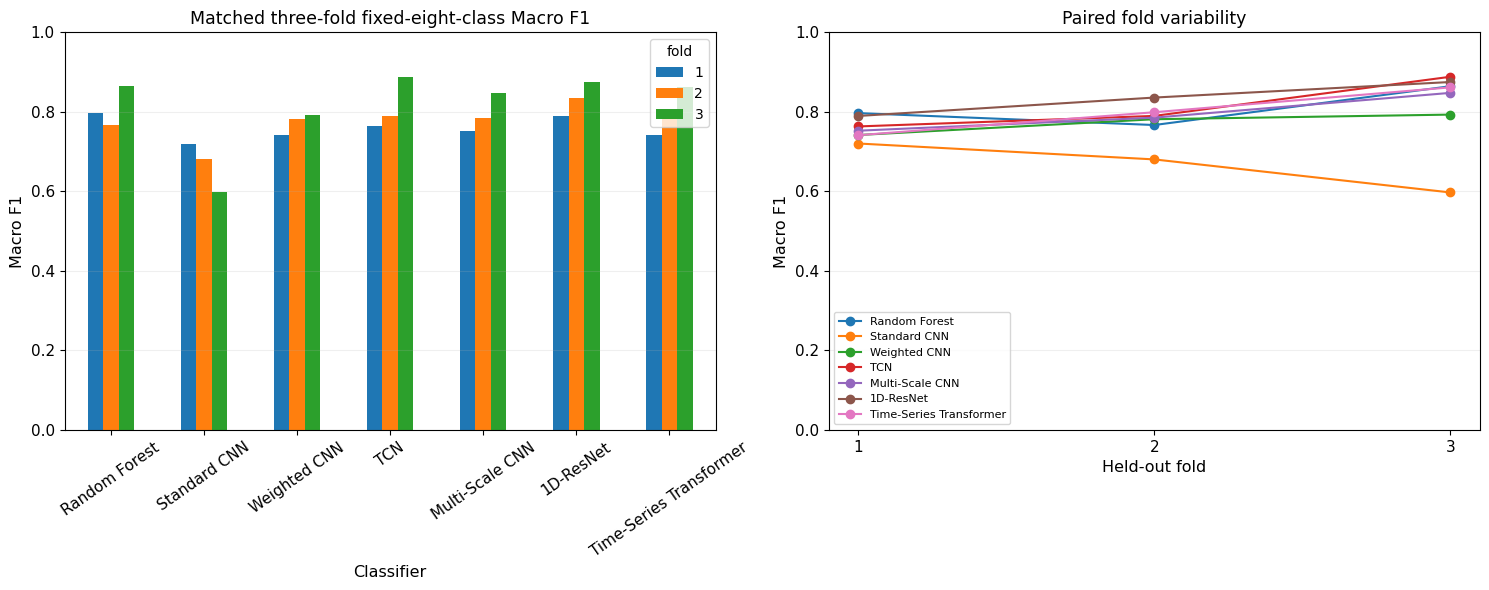

In [13]:
# ================== 12. Compare Matched Fold-Level Macro F1 ==================

# ---------------------- 1. Compare Fold-Level Macro F1 -----------------------
wide=fold_results.pivot(index="model",columns="fold",values="macro_f1"
).reindex(MODEL_NAMES)

display(wide.round(4))
wide.rename_axis("model").reset_index().to_csv(
    output_dir / "10_matched_cv_fold_comparison.csv", index=False
)

# ------------------ 2. Visualise Matched Model Performance -------------------
fig,axes=plt.subplots(1,2,figsize=(15,6))

wide.plot(kind="bar",ax=axes[0],rot=35,ylim=(0,1))
axes[0].set(title="Matched three-fold fixed-eight-class Macro F1",
            xlabel="Classifier",ylabel="Macro F1")

for model in MODEL_NAMES:
    rows=fold_results[fold_results["model"]==model].sort_values("fold")
    axes[1].plot(rows["fold"],rows["macro_f1"],marker="o",label=model)
axes[1].set(title="Paired fold variability",xlabel="Held-out fold",
            ylabel="Macro F1",ylim=(0,1),xticks=[1,2,3])
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_fold_macro_f1.png")
plt.show()


**13. Analyse Rare-Activity Errors and Confusion Matrices**

Inspect all eight classes in the saved class-metric and per-class F1 exports, with direct attention to Shuffling and both stair activities. The 500-cap cohort includes only 219 Shuffling, 192 ascending-stair and 182 descending-stair source windows. Show the focused rare-class table once, together with the per-class F1 and seven-model confusion-matrix figures. Correlated windows and low rare-class support limit generalisation.

**Observed minority-class evidence:** Shuffling has 219 evaluation windows. Its pooled F1 is 0.5032 for Random Forest, 0.3969 for 1D-ResNet and 0.3392 for TCN. These scores are not interchangeable with population-level or per-participant generalisation.

,model,activity,support,recall,f1
2,Random Forest,Shuffling,219,0.5342,0.5032
3,Random Forest,Stairs ascending,192,0.5521,0.6291
4,Random Forest,Stairs descending,182,0.4945,0.5806
10,Standard CNN,Shuffling,219,0.0000,0.0000
11,Standard CNN,Stairs ascending,192,0.1198,0.2009
12,Standard CNN,Stairs descending,182,0.2033,0.3304
18,Weighted CNN,Shuffling,219,0.1050,0.1394
19,Weighted CNN,Stairs ascending,192,0.8073,0.5688
20,Weighted CNN,Stairs descending,182,0.6374,0.6170
26,TCN,Shuffling,219,0.3973,0.3392


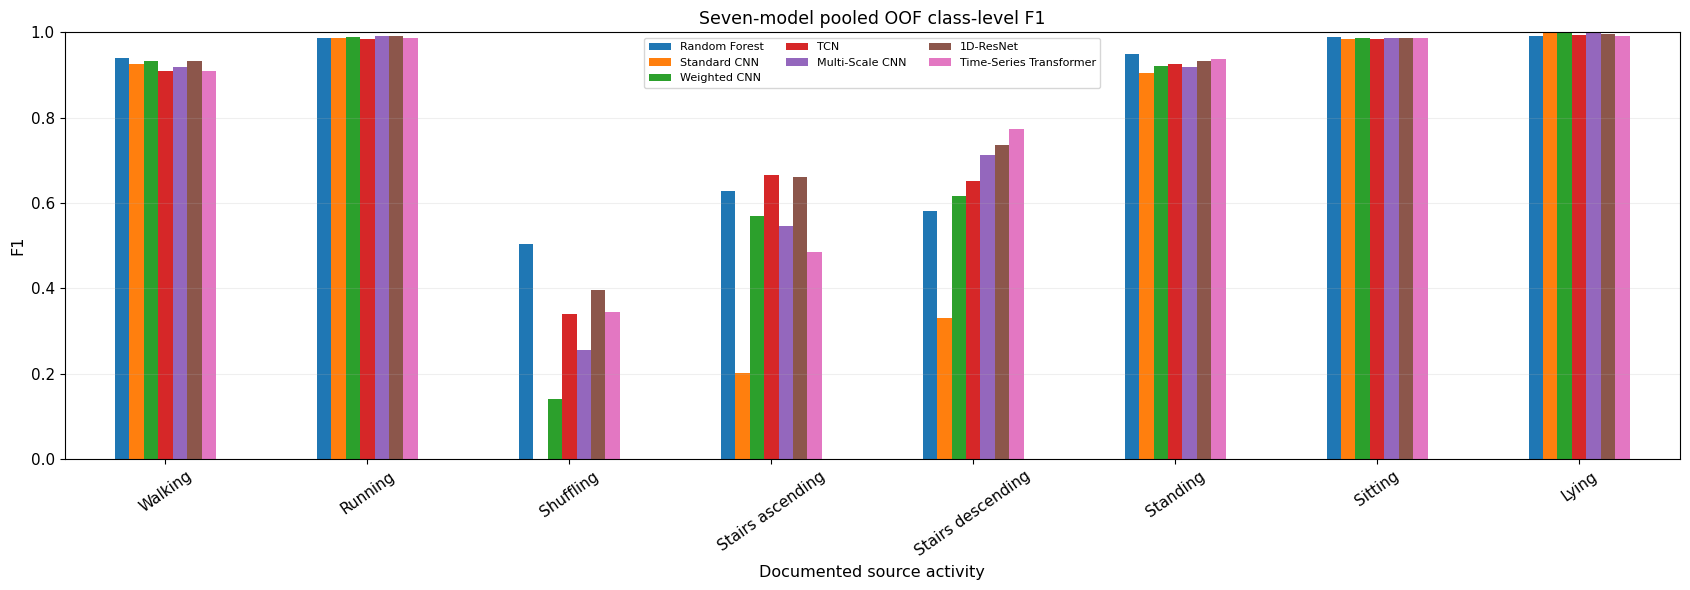

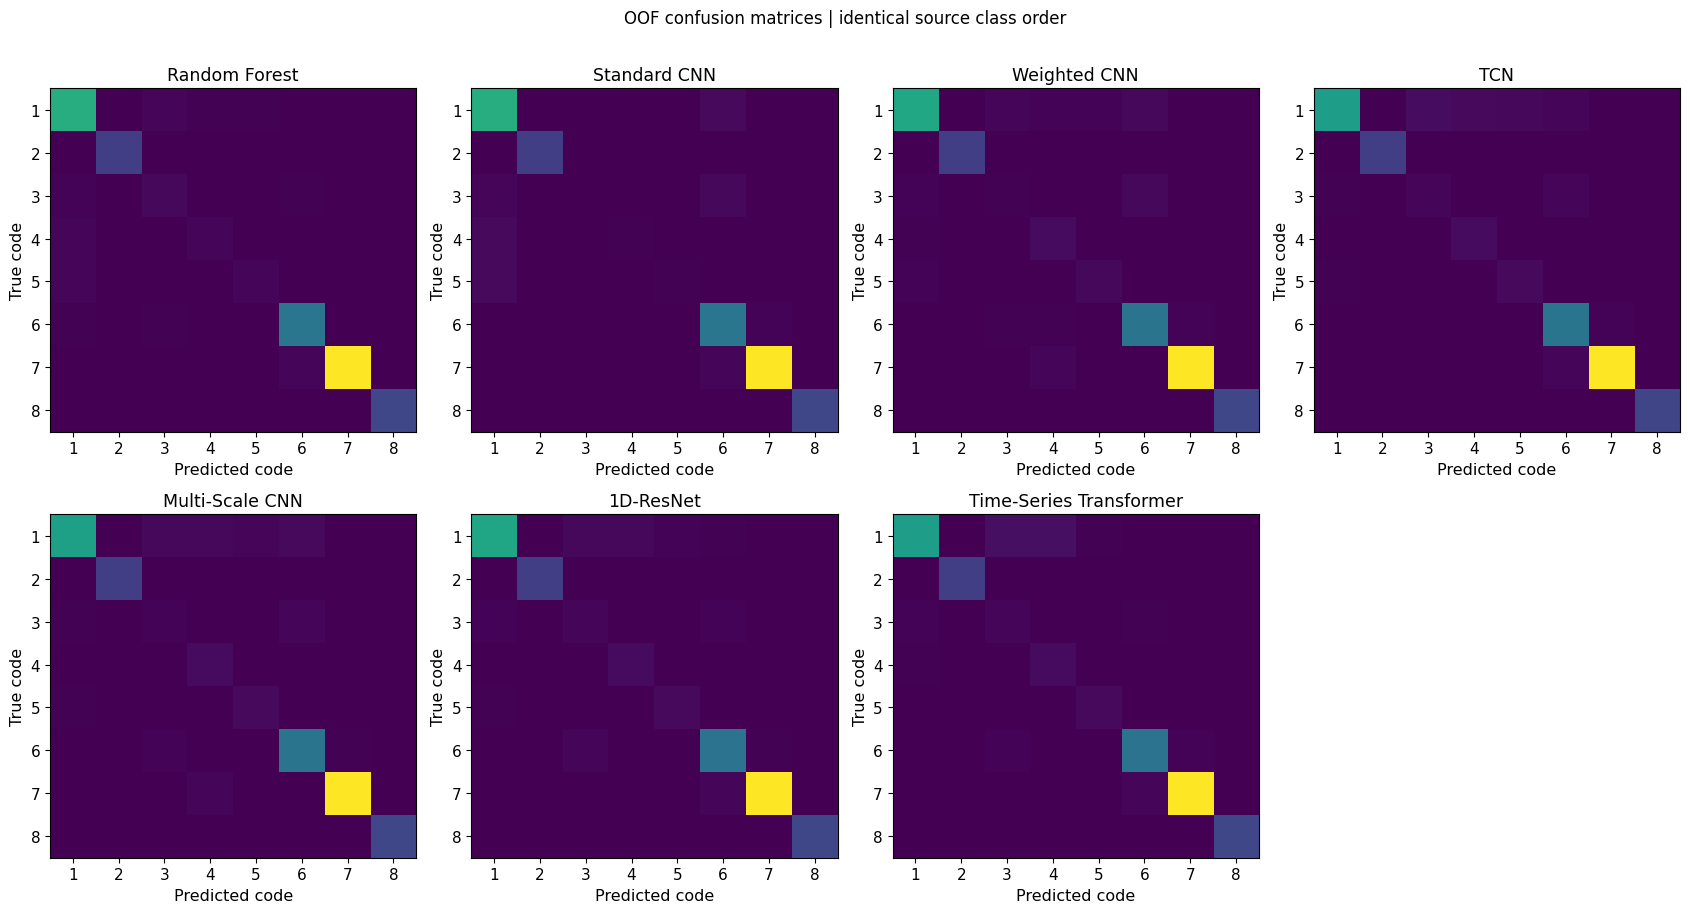

In [14]:
# ========== 13. Analyse Rare-Activity Errors and Confusion Matrices ==========

# -------------------- 1. Audit Minority-Class Predictions --------------------
class_results["activity"]=class_results["class_code"].map(ACTIVITY_NAMES)
class_results.to_csv(output_dir / "10_matched_cv_class_metrics.csv", index=False)

minority=class_results[class_results["class_code"].isin([3,4,5])]
minority.to_csv(output_dir / "10_matched_cv_minority_metrics.csv", index=False)

display(minority[["model","activity","support","recall","f1"]].round(4))

# ------------------- 2. Visualise Class F1 and Confusions --------------------
class_pivot=class_results.pivot(index="activity",columns="model",values="f1")
class_pivot=class_pivot.reindex([ACTIVITY_NAMES[c] for c in CLASSES])
class_pivot=class_pivot.reindex(columns=MODEL_NAMES)
class_pivot.rename_axis("activity").reset_index().to_csv(
    output_dir / "10_matched_cv_per_class_f1.csv", index=False
)

fig,ax=plt.subplots(figsize=(17,6))
class_pivot.plot(kind="bar",ax=ax,rot=35,ylim=(0,1))
ax.set(title="Seven-model pooled OOF class-level F1",
       xlabel="Documented source activity",ylabel="F1")
ax.legend(fontsize=8,ncol=3)
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_cv_per_class_f1.png")
plt.show()
fig,axes=plt.subplots(2,4,figsize=(17,9))

for ax,name in zip(axes.flat,MODEL_NAMES):
    matrix=confusion[name]
    ax.imshow(matrix,interpolation="nearest",aspect="auto")
    ax.set(title=name,xlabel="Predicted code",ylabel="True code")
    ax.set_xticks(range(8),CLASSES)
    ax.set_yticks(range(8),CLASSES)
for ax in list(axes.flat)[len(MODEL_NAMES):]:
    ax.axis("off")
fig.suptitle("OOF confusion matrices | identical source class order",y=1.01)
fig.tight_layout()
# ------------------- 3. Export Matched Confusion Matrices --------------------
for name, matrix in confusion.items():
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).rename_axis(
        "true_class"
    ).to_csv(output_dir / f"10_confusion_{safe_name}.csv")
save_figure(fig, output_dir / "10_matched_cv_confusion_matrices.png")
plt.show()


**14. Inspect Participant-Level Model Variation**

Compare fixed-eight-class Macro F1 at the independent participant level, not solely by pooled windows. Save the complete 29-by-seven table and visualise its variability with a heatmap. Do not repeat the full matrix as a second display when the figure and saved CSV already provide it. Participant-level results are descriptive and are not a demographic fairness analysis.

Participants per model: {'Random Forest': 29, 'Standard CNN': 29, 'Weighted CNN': 29, 'TCN': 29, 'Multi-Scale CNN': 29, '1D-ResNet': 29, 'Time-Series Transformer': 29}


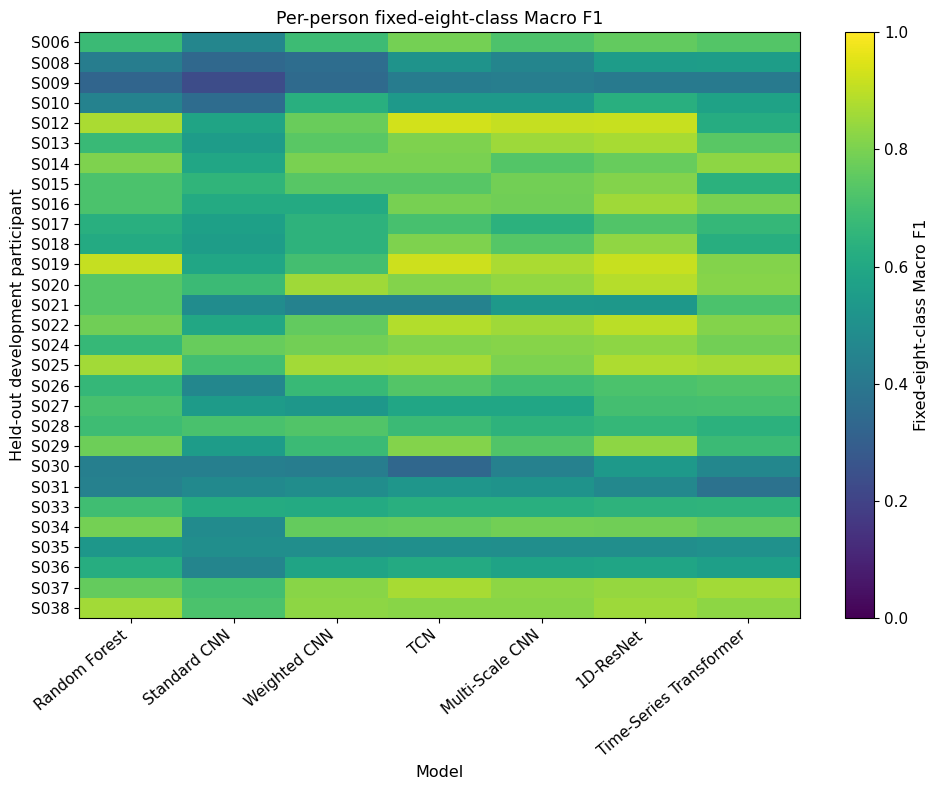

In [15]:
# =============== 14. Inspect Participant-Level Model Variation ===============

# ------------------- 1. Summarise Participant-Level Scores -------------------
individual=subject_results.pivot(
    index="subject_id",columns="model",values="macro_f1_fixed_task"
).reindex(index=DEVELOPMENT_SUBJECTS,columns=MODEL_NAMES)

individual.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "10_matched_cv_participant_comparison.csv", index=False
)
if individual.isna().any().any():
    raise ValueError("Missing held-out participant result for a model.")
print("Participants per model:",individual.notna().sum().to_dict())

# ---------------------- 2. Visualise Subject Variation -----------------------
fig,ax=plt.subplots(figsize=(10,8))

im=ax.imshow(individual.to_numpy(),aspect="auto",vmin=0,vmax=1)
ax.set_xticks(range(len(MODEL_NAMES)),MODEL_NAMES,rotation=40,ha="right")
ax.set_yticks(range(len(DEVELOPMENT_SUBJECTS)),DEVELOPMENT_SUBJECTS)
ax.set(title="Per-person fixed-eight-class Macro F1",xlabel="Model",
       ylabel="Held-out development participant")

fig.colorbar(im,ax=ax,label="Fixed-eight-class Macro F1")
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_cv_participant_f1.png")
plt.show()


**15. Report Matched Training and Inference Cost**

Report measured model-fitting time, held-out inference time and model capacity with hardware context. Neural parameter counts already appear in Section 04, so this figure focuses on **training versus inference time** rather than plotting the same architecture-capacity comparison a second time. CPU engineering timings and benchmark run costs arise from different workloads and are not directly interchangeable.

,model,total_train_s,mean_train_s_per_fold,total_validation_inference_s,trainable_parameters
0,1D-ResNet,8.343,2.781,0.108,91176
1,Multi-Scale CNN,8.696,2.899,0.115,16488
2,Random Forest,13.787,4.596,0.166,0
3,Standard CNN,4.959,1.653,0.059,12392
4,TCN,8.936,2.979,0.122,38056
5,Time-Series Transformer,13.116,4.372,0.301,38744
6,Weighted CNN,4.797,1.599,0.050,12392


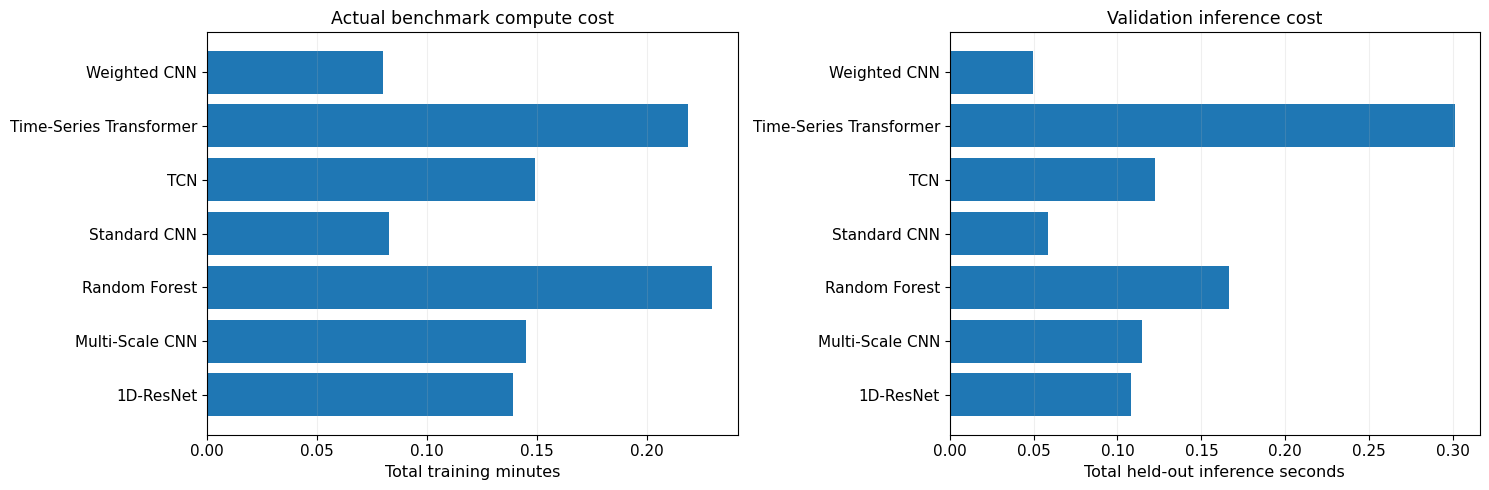

Stored source fingerprint: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Compute records are linked to the validated source fingerprint.


In [16]:
# ============== 15. Report Matched Training and Inference Cost ===============

# ---------------------- 1. Review Model Training Costs -----------------------
costs=fold_results.groupby("model",as_index=False).agg(
    total_train_s=("train_seconds","sum"),
    mean_train_s_per_fold=("train_seconds","mean"),
    total_validation_inference_s=("validation_inference_seconds","sum"),
    trainable_parameters=("trainable_parameters","max"),
)

display(costs.round(3))
costs.to_csv(output_dir / "10_matched_cv_model_compute_costs.csv", index=False)
fig,axes=plt.subplots(1,2,figsize=(15,5))

axes[0].barh(costs["model"],costs["total_train_s"]/60)
axes[0].set(xlabel="Total training minutes",title="Actual benchmark compute cost")


axes[1].barh(costs["model"],costs["total_validation_inference_s"])
axes[1].set(xlabel="Total held-out inference seconds",title="Validation inference cost")
for ax in axes: ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "10_matched_cv_compute_costs.png")
plt.show()

# ---------------------- 2. Record Benchmark Provenance -----------------------
print("Stored source fingerprint:",plan["fingerprint"])
print("Compute records are linked to the validated source fingerprint.")


**16. Interpret Development Results and Protocol Limits**

Model ranking alone does not establish a universal architecture advantage. Summarise the top observed mean Macro F1 and independently identify the model with highest pooled Shuffling F1 **from the current results**, rather than copying numerical findings from a previous execution. Retain the seven-model source-labelled decision table for inspection, but do not redisplay an essentially identical score ranking already shown in Section 11.

Key qualifications include label-blind 500-window sampling, overlapping windows, one random seed, participant/fold heterogeneity, unequal model representational capacity and the historical descriptive inspection of S023/S032. A separate multiseed study addresses robustness; this notebook does not select or evaluate the final qualified model.

**Recorded comparison (13 November 2026):** Among the seven published model summaries, 1D-ResNet has the highest three-fold mean Macro F1 (0.8336), followed by TCN (0.8138) and Random Forest (0.8094). Random Forest has the highest pooled Shuffling F1 (0.5032), illustrating that overall ranking and minority-activity performance differ. The experiment uses a single seed and participant-disjoint Development folds; these results do not constitute external validation or a significance test.

In [ ]:
# =========== 16. Interpret Development Results and Protocol Limits ===========

# -------------- 1. Interpret Model and Minority-Class Evidence ---------------
shuffling=class_results[class_results["class_code"]==3][["model","f1"]].rename(
    columns={"f1":"shuffling_pooled_f1"}
)

decision=summary.merge(shuffling,on="model",validate="one_to_one")

leader = decision.sort_values("macro_f1_mean", ascending=False).iloc[0]
rare_leader = decision.sort_values("shuffling_pooled_f1", ascending=False).iloc[0]
print(
    "Highest mean Development Macro F1:",
    leader["model"], f'{leader["macro_f1_mean"]:.4f}',
)
print(
    "Highest pooled Shuffling F1:",
    rare_leader["model"], f'{rare_leader["shuffling_pooled_f1"]:.4f}',
)

# --------------------- 2. State Development Limitations ----------------------
limitations=pd.DataFrame([
    {"issue":"Development-only model comparison","restriction":"No independent Test claim"},
    {"issue":"500-cap label-blind sampling","restriction":"Not full-data optimum or class-balanced task"},
    {"issue":"One seed and three folds","restriction":"Cannot claim strong stability or significance"},
    {"issue":"Different architecture sizes and representations","restriction":"Not isolated causal architecture advantage"},
    {"issue":"Window overlap","restriction":"No independence of window-level observations"},
    {"issue":"Original Test exploratory history","restriction":"S023/S032 not preregistered-unseen"},
])

display(limitations)

# -------------------- 3. Export Interpretation Evidence ----------------------
decision.to_csv(output_dir / "10_matched_cv_model_decision_evidence.csv", index=False)
limitations.to_csv(output_dir / "10_matched_cv_limitations.csv", index=False)


Highest mean Development Macro F1: 1D-ResNet 0.8336
Highest pooled Shuffling F1: Random Forest 0.5032


,issue,restriction
0,Development-only model comparison,No independent Test claim
1,500-cap label-blind sampling,Not full-data optimum or class-balanced task
2,One seed and three folds,Cannot claim strong stability or significance
3,Different architecture sizes and representations,Not isolated causal architecture advantage
4,Window overlap,No independence of window-level observations
5,Original Test exploratory history,S023/S032 not preregistered-unseen


**17. Validate Evidence Alignment and Package Current Outputs**

A final **targeted scientific check** ensures complete model–fold coverage, unique source-row predictions for each model, exact agreement between saved true labels and the bounded Development targets, exclusion of protected Test participants and valid fixed-task metric bounds. These checks protect the calculation; the notebook does not include duplicate administrative `PASSED` gates or fixed historical score thresholds.

Download the `10_` outputs as one bundle. The preceding execution published 35 current `10_` CSV/PNG files and saved model results. Names and explanatory displays have been revised here; the notebook should be executed again before associating newly generated notebook outputs with this edited version.

In [18]:
# ======== 17. Validate Evidence Alignment and Package Current Outputs ========

# ---------- 1. Check Complete, Participant-Safe Prediction Evidence ----------
expected_jobs = len(MODEL_NAMES) * FOLDS
expected_rows = len(X) * len(MODEL_NAMES)
if len(jobs) != expected_jobs or len(fold_results) != expected_jobs:
    raise ValueError("Benchmark model–fold evidence is incomplete.")
if len(predictions) != expected_rows:
    raise ValueError("Incomplete combined out-of-fold predictions.")
if len(subject_results) != len(DEVELOPMENT_SUBJECTS) * len(MODEL_NAMES):
    raise ValueError("Missing participant-level model evidence.")
if len(class_results) != len(MODEL_NAMES) * len(CLASSES):
    raise ValueError("Incomplete fixed-eight-class metrics.")
for name, table in predictions.groupby("model"):
    if len(table) != len(X) or not table["source_row"].is_unique:
        raise ValueError(f"{name}: incorrect held-out source-row coverage.")
    if set(table["subject_id"]) & RESERVED_TEST:
        raise ValueError(f"{name}: protected participants entered held-out evidence.")
    np.testing.assert_array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(), y
    )
if not fold_results["macro_f1"].between(0, 1).all():
    raise ValueError("Invalid fold-level Macro F1.")
if not class_results["f1"].between(0, 1).all():
    raise ValueError("Invalid activity-level F1.")

# ----------- 2. Summarise and Package Stage-Owned Research Outputs -----------
print("Development participants:", len(DEVELOPMENT_SUBJECTS))
print("Bounded source windows:", len(X))
print("Model–fold records (expected / observed):", expected_jobs, "/", len(jobs))
print("Held-out row predictions (expected / observed):", expected_rows, "/", len(predictions))
print("Participant-level scores (expected / observed):", len(DEVELOPMENT_SUBJECTS) * len(MODEL_NAMES), "/", len(subject_results))
print("Activity-level scores (expected / observed):", len(MODEL_NAMES) * len(CLASSES), "/", len(class_results))
print("Recorded evidence directory:", output_dir)
print("Qualified held-out Test evaluated by Notebook 10: NO")

download_outputs_from_colab(
    folder="wearable_activity_recognition/output", stage="10"
)


Development participants: 29
Bounded source windows: 14201
Model–fold records (expected / observed): 21 / 21
Held-out row predictions (expected / observed): 99407 / 99407
Participant-level scores (expected / observed): 203 / 203
Activity-level scores (expected / observed): 56 / 56
Recorded evidence directory: /content/human-movement-intelligence/wearable_activity_recognition/output
Qualified held-out Test evaluated by Notebook 10: NO
------------------------------------------------------------------------
Notebook stage: 10
Files packaged: 35
  + 10_architecture_capacity_cpu_timing.csv
  + 10_architecture_functional_validation.csv
  + 10_architecture_research_hypotheses.csv
  + 10_architecture_validation_cohort_summary.csv
  + 10_architecture_validation_participants.csv
  + 10_confusion_1d_resnet.csv
  + 10_confusion_multi_scale_cnn.csv
  + 10_confusion_random_forest.csv
  + 10_confusion_standard_cnn.csv
  + 10_confusion_tcn.csv
  + 10_confusion_time_series_transformer.csv
  + 10_confu